In [4]:
#ACTIVIDAD ----------------------------------------------------------------------------
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import os

# 1. Cargar el archivo
os.chdir("/Users/lleid/Downloads")
data = pd.read_excel('Amazon.xlsx')   #"C:\Users\lleid\Downloads\Amazon.xlsx"
data.head()

,Unnamed: 0,Velocidad Entrega,Precio,Durabilidad,Imagen Producto,Valor Educativo,Servicio Retorno,Tamano Paquete,Calidad Producto,Numero Estrellas
0,Adam,205,3,345,235,24,23,26,21,17
1,Anna,9,15,315,33,25,4,42,215,28
2,Bernard,17,26,285,3,43,27,41,26,33
3,Edward,135,5,355,295,18,23,39,195,17
4,Emilia,3,45,48,39,34,46,225,34,43


In [6]:
# 2. Separar nombres de clientes y datos numéricos para normalizar 
nombres = data['Unnamed: 0']              
datos_numericos = data.drop(columns=['Unnamed: 0'])   

In [13]:
# 3. Normalizar los datos 
from sklearn.preprocessing import normalize
data_scaled = normalize(datos_numericos)
data_scaled = pd.DataFrame(data_scaled, columns=datos_numericos.columns) #ponerlos en un data frame
data_scaled.head()

,Velocidad Entrega,Precio,Durabilidad,Imagen Producto,Valor Educativo,Servicio Retorno,Tamano Paquete,Calidad Producto,Numero Estrellas
0,0.438263,0.006414,0.737565,0.502399,0.051309,0.049171,0.055585,0.044895,0.036344
1,0.023235,0.038725,0.813234,0.085196,0.064542,0.010327,0.108431,0.555065,0.072287
2,0.057235,0.087535,0.959520,0.010100,0.144770,0.090902,0.138036,0.087535,0.111102
3,0.258856,0.009587,0.680696,0.565649,0.034514,0.044101,0.074781,0.373904,0.032597
4,0.011975,0.179625,0.191600,0.155675,0.135717,0.183617,0.898127,0.135717,0.171642


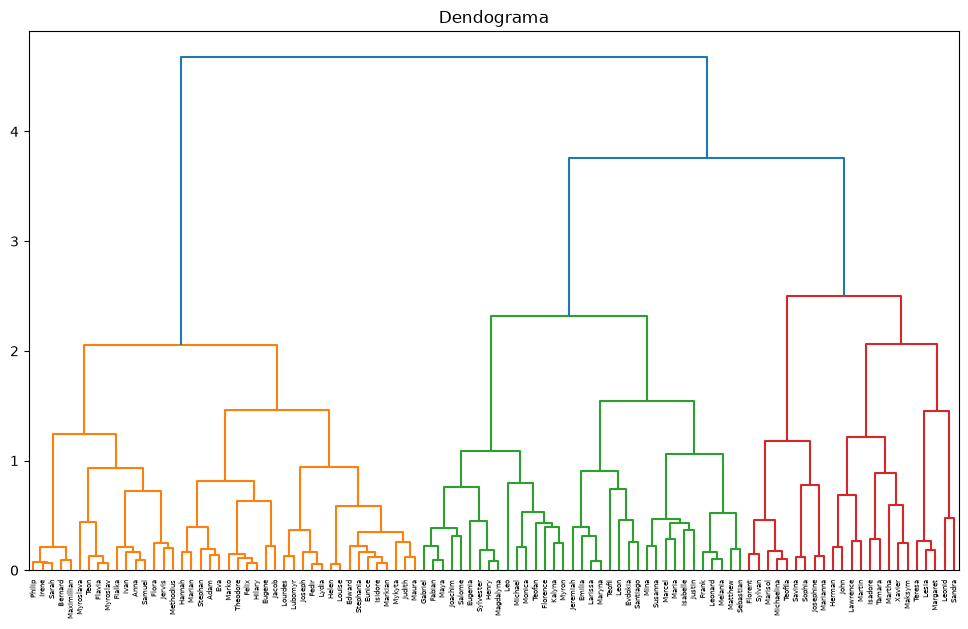

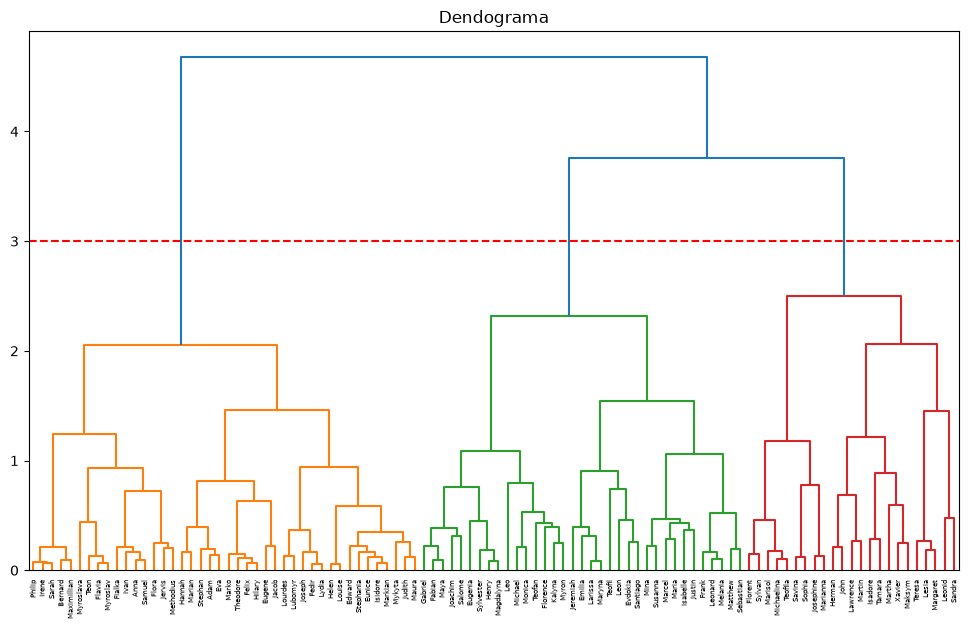

In [24]:
# 4. Dendrograma 
import scipy.cluster.hierarchy as shc
plt.figure(figsize=(12,7))
plt.title("Dendograma")
dend = shc.dendrogram(shc.linkage(data_scaled, method='ward'), labels=nombres.values) #poner el nombre de las personas
plt.show()

colores_unicos = set(dend['color_list'])
num_clusters_optimo = len(colores_unicos) - 1
num_clusters_optimo

plt.figure(figsize = (12,7))   #agregamps la linea punteada
plt.title("Dendograma")
dend = shc.dendrogram(shc.linkage(data_scaled, method = 'ward'), labels=nombres.values)
plt.axhline(y=3, color = 'r', linestyle = '--')
plt.show()

In [25]:
# 5. Aplicar Agglomerative Clustering 
from sklearn.cluster import AgglomerativeClustering
cluster = AgglomerativeClustering(n_clusters=num_clusters_optimo, metric='euclidean', linkage='ward')
grupos = cluster.fit_predict(data_scaled)
grupos

array([1, 1, 1, 1, 2, 2, 1, 2, 0, 2, 0, 2, 1, 2, 1, 1, 1, 2, 1, 1, 2, 1,
       1, 1, 1, 1, 0, 2, 1, 1, 0, 1, 1, 0, 1, 1, 2, 1, 2, 0, 2, 0, 1, 2,
       2, 2, 0, 2, 2, 0, 0, 2, 1, 1, 1, 2, 0, 2, 0, 2, 1, 0, 1, 1, 0, 0,
       2, 2, 1, 2, 1, 2, 1, 2, 0, 2, 2, 1, 2, 1, 1, 2, 1, 0, 1, 0, 2, 0,
       1, 1, 2, 0, 2, 0, 1, 2, 2, 0, 1, 0])

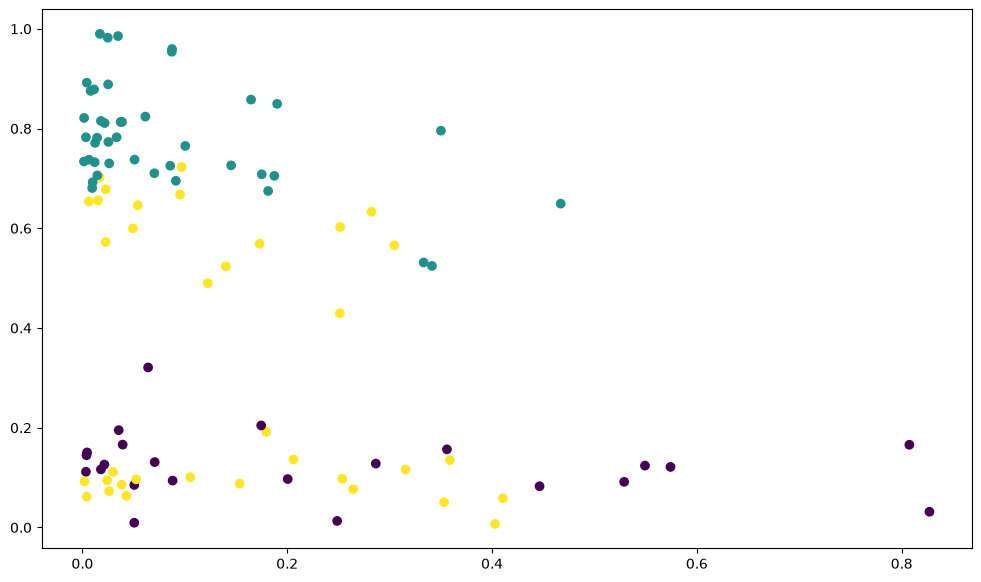

In [26]:
plt.figure(figsize = (12,7))
plt.scatter(data_scaled['Precio'],data_scaled['Durabilidad'],c = cluster.labels_)

In [27]:
# 6. Separamos en grupos pero con los nombres
dataframe = pd.DataFrame(grupos, columns=['grupo'])
dataframe2 = pd.concat([nombres, dataframe], axis=1, join='inner')
pd.options.display.max_rows = None
dataframe2

,Unnamed: 0,grupo
0,Adam,1
1,Anna,1
2,Bernard,1
3,Edward,1
4,Emilia,2
5,Fabian,2
6,Philip,1
7,Frank,2
8,Xavier,0
9,Gabriel,2


In [28]:
# 7. Consultar el cluster de los cliente de interés
for cliente in ['Salome', 'Stephania', 'Lydia']:
    fila = dataframe2[dataframe2['Unnamed: 0'] == cliente]   
    print(fila)

   Unnamed: 0  grupo
81     Salome      2
   Unnamed: 0  grupo
89  Stephania      1
   Unnamed: 0  grupo
54      Lydia      1


In [29]:
# 8. Ver quién más está en el mismo cluster que cada uno 
for cliente in ['Salome', 'Stephania', 'Lydia']:
    grupo_cliente = dataframe2.loc[dataframe2['Unnamed: 0'] == cliente, 'grupo'].values[0]
    companeros = dataframe2[(dataframe2['grupo'] == grupo_cliente) & (dataframe2['Unnamed: 0'] != cliente)]
    print(f"\n{cliente} pertenece al grupo {grupo_cliente}. Clientes en el mismo grupo:")
    print(companeros['Unnamed: 0'].tolist())


Salome pertenece al grupo 2. Clientes en el mismo grupo:
['Emilia', 'Fabian', 'Frank', 'Gabriel', 'Henry', 'Isabelle', 'Eugenia', 'Evdokia', 'Florence', 'Jeremiah', 'Joachim', 'Santiago', 'Justin', 'Kalyna', 'Larissa', 'Leon', 'Leonard', 'Leo', 'Magdalyna', 'Marcel', 'Maria', 'Maryna', 'Matthew', 'Maya', 'Melania', 'Michael', 'Mina', 'Monica', 'Myron', 'Sebastian', 'Susanna', 'Sylvester', 'Teofan', 'Teofil']

Stephania pertenece al grupo 1. Clientes en el mismo grupo:
['Adam', 'Anna', 'Bernard', 'Edward', 'Philip', 'Irene', 'Isidore', 'Joseph', 'Eugene', 'Eunice', 'Eva', 'Fedir', 'Felix', 'Fialka', 'Flavia', 'Flora', 'Hannah', 'Helen', 'Hilary', 'Lourdes', 'Ivan', 'Jacob', 'Jervis', 'Judith', 'Louise', 'Lubomyr', 'Lydia', 'Marian', 'Markian', 'Marko', 'Maura', 'Maximillian', 'Methodius', 'Mykyta', 'Myroslav', 'Myroslava', 'Samuel', 'Sarah', 'Stephan', 'Theodore', 'Teon']

Lydia pertenece al grupo 1. Clientes en el mismo grupo:
['Adam', 'Anna', 'Bernard', 'Edward', 'Philip', 'Irene', '

# ¿Qué productos le recomendaría a Salomé?

# ¿Qué productos le recomendaría a Stephania?

# Qué productos le recomendaría a Lydia?